In [1]:
import pandas as pd
import numpy as np

historical = pd.read_csv("../../data/processed/historical_audits_clean.csv")
print(historical.shape)
historical.head()

(96, 9)


,audit_period,department,previous_findings,critical_findings,mfa_adoption_pct,privileged_accounts,failed_logins,avg_resolution_days,future_high_risk
0,Q1-2023,IT,10,3,54.6,3,3,15.1,0
1,Q1-2023,Finance,7,2,57.0,18,16,12.9,0
2,Q1-2023,HR,5,0,61.3,12,28,17.0,0
3,Q1-2023,Operations,6,2,70.0,6,41,24.6,1
4,Q1-2023,Sales,4,0,87.9,12,39,25.5,0


In [2]:
def period_sort_key(p):
    q, y = p.split("-")
    return int(y) * 4 + int(q[1])

periods_sorted = sorted(historical["audit_period"].unique(), key=period_sort_key)
train_periods = periods_sorted[:12]   # oldest 12 quarters
test_periods = periods_sorted[12:]    # most recent 4 quarters

train_df = historical[historical["audit_period"].isin(train_periods)].copy()
test_df = historical[historical["audit_period"].isin(test_periods)].copy()

print("Train rows:", len(train_df), "| Test rows:", len(test_df))
print("Train periods:", train_periods)
print("Test periods:", test_periods)

Train rows: 72 | Test rows: 24
Train periods: ['Q1-2023', 'Q2-2023', 'Q3-2023', 'Q4-2023', 'Q1-2024', 'Q2-2024', 'Q3-2024', 'Q4-2024', 'Q1-2025', 'Q2-2025', 'Q3-2025', 'Q4-2025']
Test periods: ['Q1-2026', 'Q2-2026', 'Q3-2026', 'Q4-2026']


In [3]:
feature_cols = ["department", "previous_findings", "critical_findings", "mfa_adoption_pct",
                 "privileged_accounts", "failed_logins", "avg_resolution_days"]
target_col = "future_high_risk"

train_encoded = pd.get_dummies(train_df[feature_cols], columns=["department"])
test_encoded = pd.get_dummies(test_df[feature_cols], columns=["department"])
test_encoded = test_encoded.reindex(columns=train_encoded.columns, fill_value=0)  # keep columns aligned

X_train, y_train = train_encoded, train_df[target_col]
X_test, y_test = test_encoded, test_df[target_col]

print("Train class balance:\n", y_train.value_counts())
print("Test class balance:\n", y_test.value_counts())

Train class balance:
 future_high_risk
0    50
1    22
Name: count, dtype: int64
Test class balance:
 future_high_risk
0    15
1     9
Name: count, dtype: int64


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(X_train_scaled, y_train)
logreg_preds = logreg.predict(X_test_scaled)
logreg_probs = logreg.predict_proba(X_test_scaled)[:, 1]

In [5]:
from xgboost import XGBClassifier

xgb = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1,
                     random_state=42, eval_metric="logloss")
xgb.fit(X_train, y_train)
xgb_preds = xgb.predict(X_test)
xgb_probs = xgb.predict_proba(X_test)[:, 1]

In [6]:
from sklearn.metrics import (precision_score, recall_score, f1_score,
                              roc_auc_score, average_precision_score, confusion_matrix)

def evaluate(name, y_true, preds, probs):
    print(f"--- {name} ---")
    print("Precision:", round(precision_score(y_true, preds, zero_division=0), 3))
    print("Recall:", round(recall_score(y_true, preds, zero_division=0), 3))
    print("F1:", round(f1_score(y_true, preds, zero_division=0), 3))
    print("ROC-AUC:", round(roc_auc_score(y_true, probs), 3) if len(set(y_true)) > 1 else "N/A (only one class in test set)")
    print("PR-AUC:", round(average_precision_score(y_true, probs), 3) if len(set(y_true)) > 1 else "N/A")
    print("Confusion matrix:\n", confusion_matrix(y_true, preds))
    print()

evaluate("Logistic Regression (baseline)", y_test, logreg_preds, logreg_probs)
evaluate("XGBoost", y_test, xgb_preds, xgb_probs)

--- Logistic Regression (baseline) ---
Precision: 0.75
Recall: 0.333
F1: 0.462
ROC-AUC: 0.563
PR-AUC: 0.582
Confusion matrix:
 [[14  1]
 [ 6  3]]

--- XGBoost ---
Precision: 0.333
Recall: 0.222
F1: 0.267
ROC-AUC: 0.474
PR-AUC: 0.471
Confusion matrix:
 [[11  4]
 [ 7  2]]



c:\Users\Harsh Kumar\Desktop\THEMIS\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


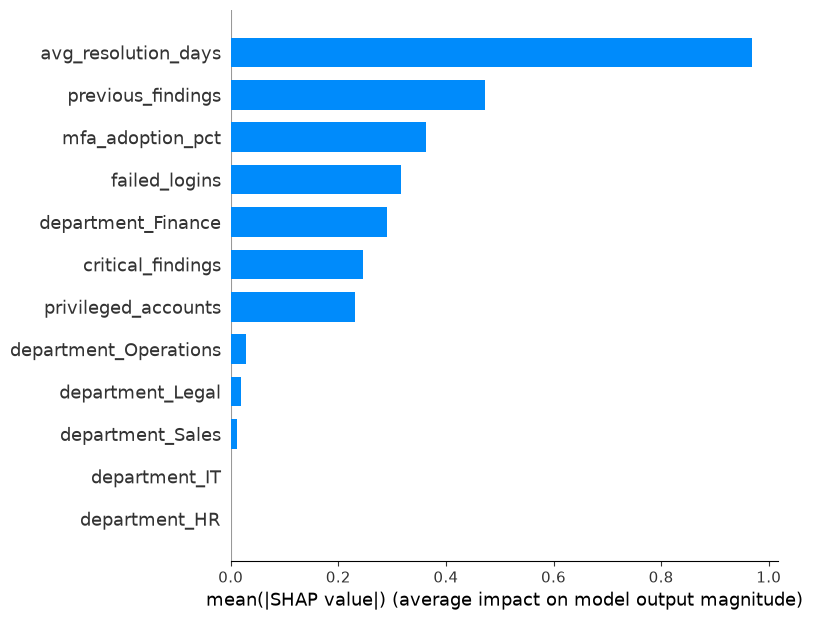

In [7]:
import shap

explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, plot_type="bar")

In [8]:
import os, joblib

os.makedirs("../../app/ml/models", exist_ok=True)
joblib.dump(xgb, "../../app/ml/models/risk_xgboost.pkl")
joblib.dump(scaler, "../../app/ml/models/risk_scaler.pkl")

print("Saved XGBoost risk model.")

Saved XGBoost risk model.
